In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

np.random.seed(42)

# Create the data folder
Path("data").mkdir(exist_ok=True)

print("Phase 2 notebook is ready!")

Phase 2 notebook is ready!


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

# Set random seed for reproducibility
np.random.seed(42)

# Dataset configuration
n = 10000
n_fraud = 300

# Generate transaction timestamps over 30 days
timestamps = pd.Timestamp("2026-09-01") + pd.to_timedelta(
    np.random.randint(0, 30 * 24 * 60, n), unit="m"
)

# Generate sender and receiver IDs
sender_ids = [f"U{np.random.randint(1, 1501):04d}" for _ in range(n)]
receiver_ids = [f"R{np.random.randint(1, 801):04d}" for _ in range(n)]

# Generate transaction amounts
amounts = np.random.lognormal(mean=5.0, sigma=0.8, size=n)
amounts = np.clip(amounts, 10, 10000).round(2)

# Assign simulated suspicious transactions
fraud_indices = np.random.choice(n, n_fraud, replace=False)
amounts[fraud_indices] = np.random.uniform(5000, 25000, n_fraud).round(2)

# Generate transaction categories
merchant_categories = np.random.choice(
    ["Shopping", "Food", "Travel", "Utilities",
     "Healthcare", "Entertainment"], n
)

transaction_types = np.random.choice(
    ["P2P", "P2M"], n, p=[0.65, 0.35]
)

locations = np.random.choice(
    ["Pune", "Mumbai", "Nagpur", "Nashik", "Other"], n
)

device_types = np.random.choice(
    ["Android", "iOS", "Web"], n, p=[0.75, 0.20, 0.05]
)

upi_channels = np.random.choice(
    ["QR", "UPI ID", "Mobile Number", "Collect Request"], n
)

# Create DataFrame
df = pd.DataFrame({
    "transaction_id": [f"TXN{i:06d}" for i in range(1, n + 1)],
    "timestamp": timestamps,
    "sender_id": sender_ids,
    "receiver_id": receiver_ids,
    "transaction_amount": amounts,
    "merchant_category": merchant_categories,
    "transaction_type": transaction_types,
    "location": locations,
    "device_type": device_types,
    "upi_channel": upi_channels
})

# Extract time features
df["hour_of_day"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.day_name()

# Create simulated labels for evaluation only
df["actual_fraud_label"] = 0
df.loc[fraud_indices, "actual_fraud_label"] = 1

# Sort transactions by timestamp
df = df.sort_values("timestamp").reset_index(drop=True)

# Save the CSV file
Path("data").mkdir(exist_ok=True)
df.to_csv("data/upi_transactions.csv", index=False)

# Display results
print("Dataset generated successfully!")
print("Total transactions:", len(df))
print("Simulated suspicious transactions:", int(df["actual_fraud_label"].sum()))
print("Normal transactions:", int((df["actual_fraud_label"] == 0).sum()))
print("Dataset shape:", df.shape)

display(df.head(10))


Dataset generated successfully!
Total transactions: 10000
Simulated suspicious transactions: 300
Normal transactions: 9700
Dataset shape: (10000, 13)


,transaction_id,timestamp,sender_id,receiver_id,transaction_amount,merchant_category,transaction_type,location,device_type,upi_channel,hour_of_day,day_of_week,actual_fraud_label
0,TXN009221,2026-09-01 00:02:00,U1292,R0116,140.70,Utilities,P2P,Nagpur,Android,Collect Request,0,Tuesday,0
1,TXN000675,2026-09-01 00:09:00,U0095,R0035,117.09,Entertainment,P2M,Other,Android,Collect Request,0,Tuesday,0
2,TXN000926,2026-09-01 00:09:00,U0486,R0112,279.81,Utilities,P2M,Other,Android,UPI ID,0,Tuesday,0
3,TXN009462,2026-09-01 00:10:00,U0399,R0408,108.41,Entertainment,P2P,Other,Android,UPI ID,0,Tuesday,0
4,TXN009370,2026-09-01 00:12:00,U0413,R0167,169.70,Travel,P2P,Other,Android,Mobile Number,0,Tuesday,0
5,TXN005262,2026-09-01 00:16:00,U0669,R0730,141.73,Food,P2P,Pune,Web,Mobile Number,0,Tuesday,0
6,TXN008457,2026-09-01 00:21:00,U0724,R0780,264.85,Shopping,P2P,Nashik,Android,Collect Request,0,Tuesday,0
7,TXN007911,2026-09-01 00:28:00,U0053,R0592,169.22,Healthcare,P2P,Pune,Android,Collect Request,0,Tuesday,0
8,TXN009722,2026-09-01 00:37:00,U1343,R0338,137.46,Travel,P2M,Other,iOS,Collect Request,0,Tuesday,0
9,TXN007453,2026-09-01 00:48:00,U1460,R0779,81.51,Entertainment,P2M,Mumbai,Android,Collect Request,0,Tuesday,0


In [ ]:
import os
import pandas as pd
import numpy as np
from pathlib import Path
from google.colab import files

# Ensure the data directory exists
Path("data").mkdir(exist_ok=True)

# If the file is missing due to a runtime reset, regenerate it inline
if not os.path.exists("data/upi_transactions.csv"):
    print("Dataset missing due to runtime reset. Regenerating 'data/upi_transactions.csv'...")

    # Set random seed for reproducibility
    np.random.seed(42)
    n = 10000
    n_fraud = 300

    # Generate transaction timestamps over 30 days
    timestamps = pd.Timestamp("2026-09-01") + pd.to_timedelta(
        np.random.randint(0, 30 * 24 * 60, n), unit="m"
    )

    # Generate sender and receiver IDs
    sender_ids = [f"U{np.random.randint(1, 1501):04d}" for _ in range(n)]
    receiver_ids = [f"R{np.random.randint(1, 801):04d}" for _ in range(n)]

    # Generate transaction amounts
    amounts = np.random.lognormal(mean=5.0, sigma=0.8, size=n)
    amounts = np.clip(amounts, 10, 10000).round(2)

    # Assign simulated suspicious transactions
    fraud_indices = np.random.choice(n, n_fraud, replace=False)
    amounts[fraud_indices] = np.random.uniform(5000, 25000, n_fraud).round(2)

    # Generate categorical columns
    merchant_categories = np.random.choice(["Shopping", "Food", "Travel", "Utilities", "Healthcare", "Entertainment"], n)
    transaction_types = np.random.choice(["P2P", "P2M"], n, p=[0.65, 0.35])
    locations = np.random.choice(["Pune", "Mumbai", "Nagpur", "Nashik", "Other"], n)
    device_types = np.random.choice(["Android", "iOS", "Web"], n, p=[0.75, 0.20, 0.05])
    upi_channels = np.random.choice(["QR", "UPI ID", "Mobile Number", "Collect Request"], n)

    # Create DataFrame
    df = pd.DataFrame({
        "transaction_id": [f"TXN{i:06d}" for i in range(1, n + 1)],
        "timestamp": timestamps,
        "sender_id": sender_ids,
        "receiver_id": receiver_ids,
        "transaction_amount": amounts,
        "merchant_category": merchant_categories,
        "transaction_type": transaction_types,
        "location": locations,
        "device_type": device_types,
        "upi_channel": upi_channels
    })

    # Extract time features
    df["hour_of_day"] = df["timestamp"].dt.hour
    df["day_of_week"] = df["timestamp"].dt.day_name()
    df["actual_fraud_label"] = 0
    df.loc[fraud_indices, "actual_fraud_label"] = 1
    df = df.sort_values("timestamp").reset_index(drop=True)

    # Save to disk
    df.to_csv("data/upi_transactions.csv", index=False)
    print("Dataset successfully regenerated!")

# Trigger file download
files.download("data/upi_transactions.csv")

Dataset missing due to runtime reset. Regenerating 'data/upi_transactions.csv'...
Dataset successfully regenerated!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# PHASE 3: DATA CLEANING

import pandas as pd
import numpy as np

# Load the saved dataset
df = pd.read_csv("data/upi_transactions.csv")

# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Dataset shape:", df.shape)

print("\n--- Dataset Information ---")
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print("Duplicate rows:", df.duplicated().sum())

print("\n--- Duplicate Transaction IDs ---")
print(df["transaction_id"].duplicated().sum())

print("\n--- Transaction Amount Summary ---")
print(df["transaction_amount"].describe())

print("\n--- Simulated Label Distribution ---")
print(df["actual_fraud_label"].value_counts())


Dataset shape: (10000, 13)

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   transaction_id      10000 non-null  object        
 1   timestamp           10000 non-null  datetime64[ns]
 2   sender_id           10000 non-null  object        
 3   receiver_id         10000 non-null  object        
 4   transaction_amount  10000 non-null  float64       
 5   merchant_category   10000 non-null  object        
 6   transaction_type    10000 non-null  object        
 7   location            10000 non-null  object        
 8   device_type         10000 non-null  object        
 9   upi_channel         10000 non-null  object        
 10  hour_of_day         10000 non-null  int64         
 11  day_of_week         10000 non-null  object        
 12  actual_fraud_label  10000 non-null  int64      

In [ ]:

# Work on a separate cleaned copy
clean_df = df.copy()

# Remove duplicate transaction IDs, if any
clean_df = clean_df.drop_duplicates(
    subset="transaction_id",
    keep="first"
)

# Remove rows with missing essential fields
essential_columns = [
    "transaction_id",
    "timestamp",
    "sender_id",
    "receiver_id",
    "transaction_amount"
]

clean_df = clean_df.dropna(subset=essential_columns)

# Keep only valid positive transaction amounts
clean_df = clean_df[
    clean_df["transaction_amount"] > 0
].copy()

# Validate simulated labels
clean_df["actual_fraud_label"] = (
    clean_df["actual_fraud_label"].astype(int)
)

# Save the cleaned data
clean_df.to_csv("data/processed_transactions.csv", index=False)

print("Data cleaning completed!")
print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Missing values remaining:", clean_df.isnull().sum().sum())
print("Saved: data/processed_transactions.csv")


Data cleaning completed!
Original rows: 10000
Cleaned rows: 10000
Missing values remaining: 0
Saved: data/processed_transactions.csv


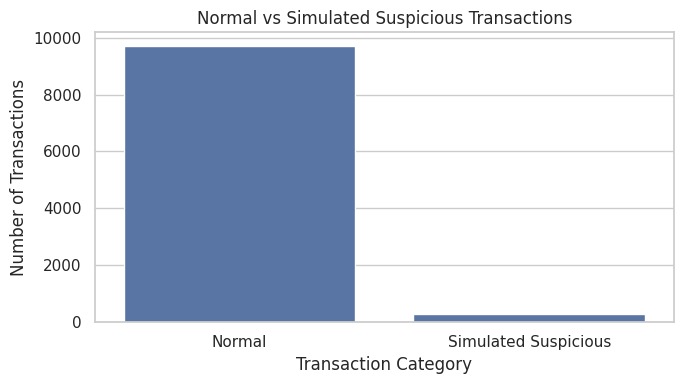

actual_fraud_label
Normal                  9700
Simulated Suspicious     300
Name: count, dtype: int64


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

label_counts = clean_df["actual_fraud_label"].map({
    0: "Normal",
    1: "Simulated Suspicious"
}).value_counts()

plt.figure(figsize=(7, 4))
sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)
plt.title("Normal vs Simulated Suspicious Transactions")
plt.xlabel("Transaction Category")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

print(label_counts)


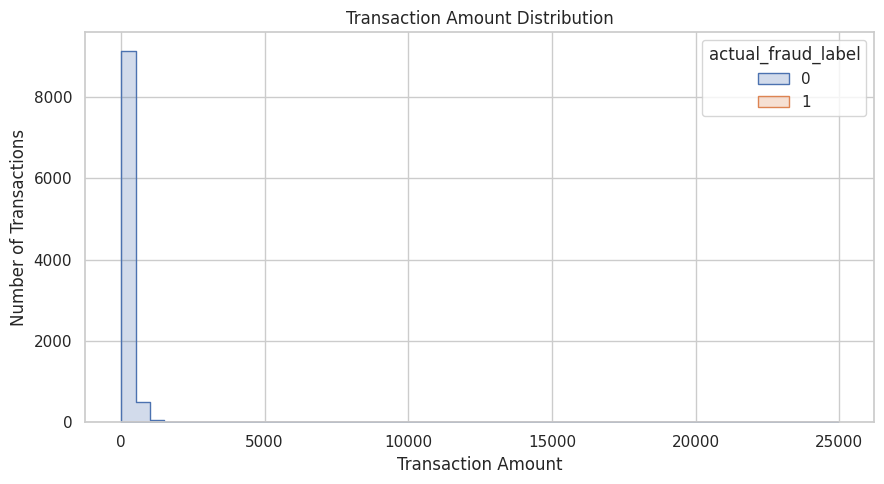

In [ ]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=clean_df,
    x="transaction_amount",
    hue="actual_fraud_label",
    bins=50,
    element="step",
    stat="count"
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


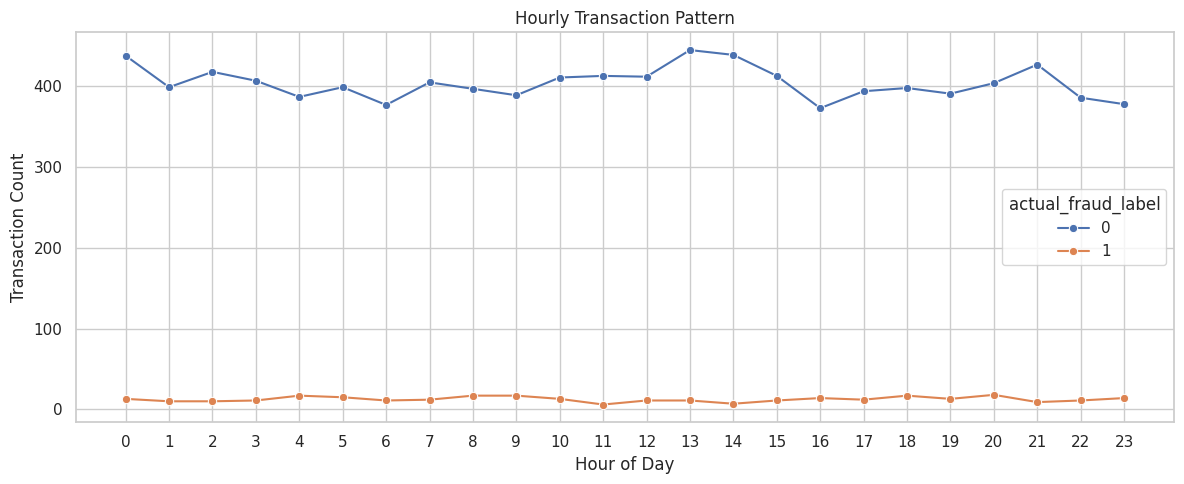

In [ ]:

hourly_data = (
    clean_df.groupby(
        ["hour_of_day", "actual_fraud_label"]
    )
    .size()
    .reset_index(name="transaction_count")
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_data,
    x="hour_of_day",
    y="transaction_count",
    hue="actual_fraud_label",
    marker="o"
)

plt.title("Hourly Transaction Pattern")
plt.xlabel("Hour of Day")
plt.ylabel("Transaction Count")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import numpy as np

# Load the cleaned dataset
df = pd.read_csv("data/processed_transactions.csv")

# Calculate IQR thresholds for transaction amounts
Q1 = df["transaction_amount"].quantile(0.25)
Q3 = df["transaction_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag unusually low or high amounts
df["iqr_flag"] = (
    (df["transaction_amount"] < lower_bound) |
    (df["transaction_amount"] > upper_bound)
).astype(int)

# Display results
print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))

print("\nIQR detection results:")
print(df["iqr_flag"].value_counts())

print("\nSample flagged transactions:")
display(
    df[df["iqr_flag"] == 1][
        ["transaction_id", "timestamp",
         "transaction_amount", "iqr_flag"]
    ].head(10)
)

# Save the results
df.to_csv("data/iqr_results.csv", index=False)

print("\nSaved results to data/iqr_results.csv")


Q1: 88.56
Q3: 273.12
IQR: 184.55
Lower bound: -188.26
Upper bound: 549.94

IQR detection results:
iqr_flag
0    9230
1     770
Name: count, dtype: int64

Sample flagged transactions:


,transaction_id,timestamp,transaction_amount,iqr_flag
17,TXN007699,2026-09-01 01:14:00,948.18,1
22,TXN002697,2026-09-01 01:37:00,611.53,1
29,TXN008577,2026-09-01 02:12:00,14476.07,1
41,TXN000065,2026-09-01 02:41:00,10274.33,1
48,TXN000313,2026-09-01 03:10:00,23053.16,1
50,TXN004322,2026-09-01 03:12:00,551.17,1
75,TXN001907,2026-09-01 05:02:00,16631.42,1
90,TXN004488,2026-09-01 06:05:00,7611.03,1
102,TXN003909,2026-09-01 06:46:00,564.49,1
117,TXN005686,2026-09-01 08:27:00,745.37,1



Saved results to data/iqr_results.csv


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix

print("IQR evaluation against simulated labels:\n")

print(classification_report(
    df["actual_fraud_label"],
    df["iqr_flag"],
    target_names=["Normal", "Simulated Suspicious"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    df["actual_fraud_label"],
    df["iqr_flag"]
))


IQR evaluation against simulated labels:

                      precision    recall  f1-score   support

              Normal       1.00      0.95      0.98      9700
Simulated Suspicious       0.39      1.00      0.56       300

            accuracy                           0.95     10000
           macro avg       0.69      0.98      0.77     10000
        weighted avg       0.98      0.95      0.96     10000

Confusion matrix:
[[9230  470]
 [   0  300]]


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/iqr_results.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 14)


,transaction_id,timestamp,sender_id,receiver_id,transaction_amount,merchant_category,transaction_type,location,device_type,upi_channel,hour_of_day,day_of_week,actual_fraud_label,iqr_flag
0,TXN009221,2026-09-01 00:02:00,U1292,R0116,140.70,Utilities,P2P,Nagpur,Android,Collect Request,0,Tuesday,0,0
1,TXN000675,2026-09-01 00:09:00,U0095,R0035,117.09,Entertainment,P2M,Other,Android,Collect Request,0,Tuesday,0,0
2,TXN000926,2026-09-01 00:09:00,U0486,R0112,279.81,Utilities,P2M,Other,Android,UPI ID,0,Tuesday,0,0
3,TXN009462,2026-09-01 00:10:00,U0399,R0408,108.41,Entertainment,P2P,Other,Android,UPI ID,0,Tuesday,0,0
4,TXN009370,2026-09-01 00:12:00,U0413,R0167,169.70,Travel,P2P,Other,Android,Mobile Number,0,Tuesday,0,0


In [ ]:
from sklearn.ensemble import IsolationForest

# Convert day_of_week to numeric representation (0-6) to allow numerical calculations
if 'day_of_week' in df.columns and df['day_of_week'].dtype == 'object':
    # We can map day names to numbers or retrieve them from the original datetime if preferred.
    # Since we loaded it from CSV, converting it using pandas categorical codes is a clean way:
    df['day_of_week_numeric'] = pd.Categorical(df['day_of_week'],
                                            categories=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
                                            ordered=True).codes

# Select numerical features
features = [
    "transaction_amount",
    "hour_of_day",
    "day_of_week_numeric"
]

X = df[features].copy()

# Handle missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Calculate median only on numeric columns
medians = X.median()
X = X.fillna(medians)

print("Features selected:", features)
print("Missing values remaining:", X.isna().sum().sum())

Features selected: ['transaction_amount', 'hour_of_day', 'day_of_week_numeric']
Missing values remaining: 0


In [ ]:
model = IsolationForest(
    n_estimators=100,
    contamination=0.03,
    random_state=42
)

model.fit(X)

# Predict: 1 = normal, -1 = anomaly
predictions = model.predict(X)

# Convert to project labels: 0 = normal, 1 = flagged
df["isolation_forest_flag"] = (predictions == -1).astype(int)

print("Isolation Forest results:")
print(df["isolation_forest_flag"].value_counts())

display(
    df[df["isolation_forest_flag"] == 1][
        ["transaction_id", "transaction_amount",
         "hour_of_day", "day_of_week",
         "isolation_forest_flag"]
    ].head(10)
)

Isolation Forest results:
isolation_forest_flag
0    9700
1     300
Name: count, dtype: int64


,transaction_id,transaction_amount,hour_of_day,day_of_week,isolation_forest_flag
29,TXN008577,14476.07,2,Tuesday,1
41,TXN000065,10274.33,2,Tuesday,1
48,TXN000313,23053.16,3,Tuesday,1
75,TXN001907,16631.42,5,Tuesday,1
90,TXN004488,7611.03,6,Tuesday,1
162,TXN000312,17267.31,11,Tuesday,1
239,TXN000680,6959.81,16,Tuesday,1
318,TXN000587,10230.95,22,Tuesday,1
359,TXN009807,7138.40,1,Wednesday,1
375,TXN006268,19860.93,1,Wednesday,1


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("Isolation Forest evaluation:\n")

print(
    classification_report(
        df["actual_fraud_label"],
        df["isolation_forest_flag"],
        target_names=["Normal", "Simulated Suspicious"],
        zero_division=0
    )
)

print("Confusion matrix:")
print(
    confusion_matrix(
        df["actual_fraud_label"],
        df["isolation_forest_flag"]
    )
)

Isolation Forest evaluation:

                      precision    recall  f1-score   support

              Normal       1.00      1.00      1.00      9700
Simulated Suspicious       0.97      0.97      0.97       300

            accuracy                           1.00     10000
           macro avg       0.99      0.99      0.99     10000
        weighted avg       1.00      1.00      1.00     10000

Confusion matrix:
[[9692    8]
 [   8  292]]


In [ ]:
print("IQR flagged transactions:",
      df["iqr_flag"].sum())

print("Isolation Forest flagged transactions:",
      df["isolation_forest_flag"].sum())

print("Flagged by both methods:",
      ((df["iqr_flag"] == 1) &
       (df["isolation_forest_flag"] == 1)).sum())

print("Flagged only by IQR:",
      ((df["iqr_flag"] == 1) &
       (df["isolation_forest_flag"] == 0)).sum())

print("Flagged only by Isolation Forest:",
      ((df["iqr_flag"] == 0) &
       (df["isolation_forest_flag"] == 1)).sum())

IQR flagged transactions: 770
Isolation Forest flagged transactions: 300
Flagged by both methods: 300
Flagged only by IQR: 470
Flagged only by Isolation Forest: 0


In [ ]:
df.to_csv("data/isolation_forest_results.csv", index=False)

print("Saved: data/isolation_forest_results.csv")

Saved: data/isolation_forest_results.csv


In [ ]:
import pandas as pd
import numpy as np

# Corrected the filename from final_fraud_risk_results.csv to isolation_forest_results.csv
df = pd.read_csv("data/isolation_forest_results.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (10000, 16)
Columns: ['transaction_id', 'timestamp', 'sender_id', 'receiver_id', 'transaction_amount', 'merchant_category', 'transaction_type', 'location', 'device_type', 'upi_channel', 'hour_of_day', 'day_of_week', 'actual_fraud_label', 'iqr_flag', 'day_of_week_numeric', 'isolation_forest_flag']


,transaction_id,timestamp,sender_id,receiver_id,transaction_amount,merchant_category,transaction_type,location,device_type,upi_channel,hour_of_day,day_of_week,actual_fraud_label,iqr_flag,day_of_week_numeric,isolation_forest_flag
0,TXN009221,2026-09-01 00:02:00,U1292,R0116,140.70,Utilities,P2P,Nagpur,Android,Collect Request,0,Tuesday,0,0,1,0
1,TXN000675,2026-09-01 00:09:00,U0095,R0035,117.09,Entertainment,P2M,Other,Android,Collect Request,0,Tuesday,0,0,1,0
2,TXN000926,2026-09-01 00:09:00,U0486,R0112,279.81,Utilities,P2M,Other,Android,UPI ID,0,Tuesday,0,0,1,0
3,TXN009462,2026-09-01 00:10:00,U0399,R0408,108.41,Entertainment,P2P,Other,Android,UPI ID,0,Tuesday,0,0,1,0
4,TXN009370,2026-09-01 00:12:00,U0413,R0167,169.70,Travel,P2P,Other,Android,Mobile Number,0,Tuesday,0,0,1,0


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Calculate risk score as the sum of IQR and Isolation Forest flags
# 0 = not flagged, 1 = flagged by one method, 2 = flagged by both
df["risk_score"] = df["iqr_flag"] + df["isolation_forest_flag"]

# 1 = flagged for review (risk score >= 1); 0 = low risk
df["combined_prediction"] = (df["risk_score"] >= 1).astype(int)

y_true = df["actual_fraud_label"]
y_pred = df["combined_prediction"]

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Simulated Suspicious"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy: 0.953

Classification Report:
                      precision    recall  f1-score   support

              Normal       1.00      0.95      0.98      9700
Simulated Suspicious       0.39      1.00      0.56       300

            accuracy                           0.95     10000
           macro avg       0.69      0.98      0.77     10000
        weighted avg       0.98      0.95      0.96     10000

Confusion Matrix:
[[9230  470]
 [   0  300]]


In [ ]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

detection_rate = tp / (tp + fn) if (tp + fn) else 0
false_positive_rate = fp / (fp + tn) if (fp + tn) else 0
precision = tp / (tp + fp) if (tp + fp) else 0

print("True Positives:", tp)
print("False Positives:", fp)
print("True Negatives:", tn)
print("False Negatives:", fn)
print("Detection Rate / Recall:", round(detection_rate, 4))
print("False Positive Rate:", round(false_positive_rate, 4))
print("Precision:", round(precision, 4))

True Positives: 300
False Positives: 470
True Negatives: 9230
False Negatives: 0
Detection Rate / Recall: 1.0
False Positive Rate: 0.0485
Precision: 0.3896


In [ ]:
print("Average transaction amount by risk score:")

display(
    df.groupby("risk_score")["transaction_amount"]
      .agg(["count", "mean", "median", "max"])
      .round(2)
)

Average transaction amount by risk score:


,count,mean,median,max
risk_score,,,,
0,9230,173.33,142.00,549.91
1,470,879.43,709.91,7001.32
2,300,14756.31,14491.15,24961.17


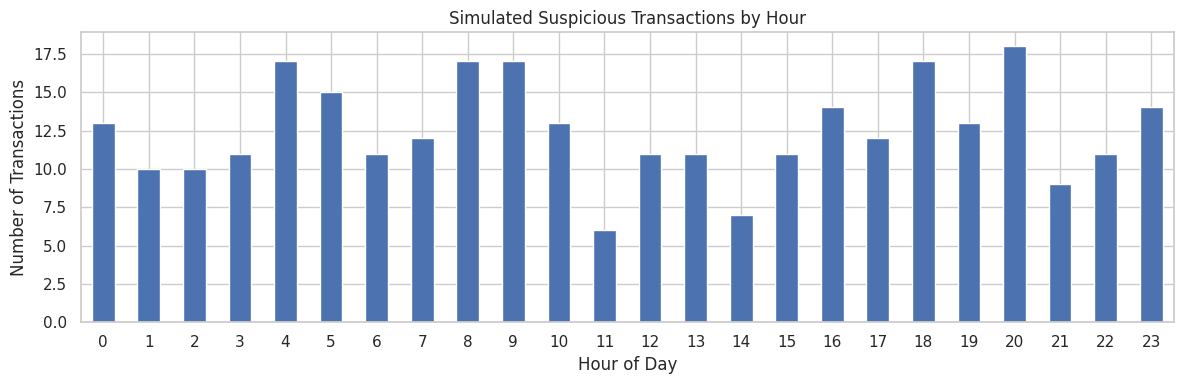

In [ ]:
suspicious_by_hour = (
    df[df["actual_fraud_label"] == 1]
    .groupby("hour_of_day")
    .size()
    .reindex(range(24), fill_value=0)
)

suspicious_by_hour.plot(kind="bar", figsize=(12, 4))
plt.title("Simulated Suspicious Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv("data/evaluated_fraud_results.csv", index=False)
print("Saved: data/evaluated_fraud_results.csv")

Saved: data/evaluated_fraud_results.csv


In [ ]:
from google.colab import files

files.download("data/evaluated_fraud_results.csv")

FileNotFoundError: Cannot find file: data/evaluated_fraud_results.csv